# LaSOT EDA (full-overlap protocol, part-1 classes only)
All logic lives in `src/`; configure classes and paths in `src/config.py`.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src").exists():       # find repo root whether run from src/eda or notebooks
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from src import config as C
from src.data.lasot import load_classes, read_split
from src.eda import stats, plots
pd.set_option("display.width", 160)
C.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("data:", C.DATA_ROOT, "| classes:", C.CLASSES)

data: C:\Users\Mariia Hamaniuk\Desktop\jepa\Object-Tracking\data | classes: ['airplane', 'basketball', 'bear', 'bicycle', 'bird', 'boat', 'book', 'bottle', 'bus', 'car', 'cat', 'cattle', 'chameleon', 'coin', 'crab', 'crocodile', 'cup', 'deer', 'dog', 'drone', 'electricfan', 'elephant', 'flag', 'fox', 'frog', 'gametarget', 'gecko', 'giraffe', 'goldfish', 'gorilla', 'guitar', 'hand', 'hat', 'helmet', 'hippo', 'horse', 'kangaroo', 'kite', 'leopard', 'licenseplate', 'lion', 'lizard', 'microphone', 'monkey', 'motorcycle', 'mouse', 'person', 'pig', 'pool', 'rabbit', 'racing', 'robot', 'rubicCube', 'sepia', 'shark', 'sheep', 'skateboard', 'spider', 'squirrel', 'surfboard', 'swing', 'tank', 'tiger', 'train', 'truck', 'turtle', 'umbrella', 'volleyball', 'yoyo', 'zebra']


## 1. Load and validate

In [3]:
seqs = load_classes(C.DATA_ROOT, C.CLASSES)
print(len(seqs), "sequences")
for s in seqs:
    if s.issues:
        print(s.name, "->", s.issues)

1400 sequences
airplane-2 -> ['170 absent frames with non-empty box']
airplane-4 -> ['20 absent frames with non-empty box']
airplane-14 -> ['4 absent frames with non-empty box']
airplane-15 -> ['37 absent frames with non-empty box']
airplane-18 -> ['4 absent frames with non-empty box']
basketball-1 -> ['3 absent frames with non-empty box']
basketball-2 -> ['55 absent frames with non-empty box']
basketball-4 -> ['335 absent frames with non-empty box']
basketball-5 -> ['225 absent frames with non-empty box']
basketball-6 -> ['68 absent frames with non-empty box']
basketball-7 -> ['34 absent frames with non-empty box']
basketball-8 -> ['22 absent frames with non-empty box']
basketball-9 -> ['9 absent frames with non-empty box']
basketball-10 -> ['126 absent frames with non-empty box']
basketball-11 -> ['59 absent frames with non-empty box']
basketball-12 -> ['65 absent frames with non-empty box']
basketball-13 -> ['776 absent frames with non-empty box']
basketball-14 -> ['46 absent frames

In [4]:
seqs_df = stats.sequence_table(seqs)
frames = stats.frame_table(seqs)
seqs_df.drop(columns="nlp").head()

,cls,seq,n_frames,duration_s,width,height,n_foc,n_oov,n_both,frac_foc,frac_oov,frac_absent,n_foc_episodes,n_oov_episodes,max_foc_len,max_oov_len,first_absence_pos,has_issues,resolution
0,airplane,airplane-1,2788,92.933333,640,360,0,0,0,0.000000,0.0,0.000000,0,0,0,0,NaN,False,640x360
1,airplane,airplane-2,8301,276.700000,1280,720,170,0,0,0.020479,0.0,0.020479,2,0,121,0,0.492832,True,1280x720
2,airplane,airplane-3,2040,68.000000,1280,720,0,0,0,0.000000,0.0,0.000000,0,0,0,0,NaN,False,1280x720
3,airplane,airplane-4,5141,171.366667,1280,720,20,0,0,0.003890,0.0,0.003890,2,0,15,0,0.290799,True,1280x720
4,airplane,airplane-5,5923,197.433333,1280,720,0,0,0,0.000000,0.0,0.000000,0,0,0,0,NaN,False,1280x720


## 2. Target size and aspect ratio (present frames only)

c:\Users\Mariia Hamaniuk\Desktop\jepa\Object-Tracking\src\eda\plots.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


cls                 airplane    basketball          bear       bicycle          bird          boat          book        bottle           bus           car  \
rel_area count  85681.000000  45078.000000  53645.000000  40066.000000  48478.000000  49695.000000  41391.000000  46377.000000  61044.000000  53929.000000   
         mean       0.045240      0.008320      0.130944      0.078780      0.100255      0.095920      0.259291      0.124922      0.093437      0.041895   
         std        0.069720      0.012409      0.149914      0.103075      0.106907      0.111058      0.248388      0.135100      0.127101      0.088616   
         min        0.000001      0.000130      0.000334      0.000197      0.000833      0.000065      0.000719      0.000088      0.000342      0.000001   
         25%        0.006466      0.002605      0.042014      0.016514      0.028760      0.019124      0.044815      0.033242      0.012960      0.005165   
         50%        0.017448      0.005556      0.086158      0.034170      0.058056      0.048216      0.186590      0.088993      0.038298      0.015299   
         75%        0.047995      0.008590      0.134528      0.095592      0.127577      0.136970      0.323678      0.168559      0.129919      0.037643   
         max        0.556927      0.138125      0.781874      0.668138      0.622448      0.725473      0.997831      0.997831      0.924878      0.637891   
aspect   count  85681.000000  45078.000000  53645.000000  40066.000000  48478.000000  49695.000000  41391.000000  46377.000000  61044.000000  53929.000000   
         mean       1.981050      1.010476      1.006909      1.007512      1.121037      1.978683      1.191023      0.855894      1.030755      1.609335   
         std        1.227766      0.203072      0.515321      0.487743      0.666914      1.377764      0.567344      0.814040      0.356112      0.522603   
         min        0.197183      0.082707      0.043243      0.157233      0.204545      0.242678      0.080321      0.001931      0.081081      0.025641   
         25%        1.032258      0.965517      0.619355      0.617647      0.579710      1.011561      0.753148      0.330189      0.864542      1.325581   
         50%        1.555556      1.000000      0.912281      0.936306      0.983562      1.667984      0.976562      0.482821      0.965035      1.500000   
         75%        2.804348      1.037736      1.260000      1.321120      1.464881      2.747422      1.489726      1.086957      1.097222      1.904762   
         max        9.767123      8.000000      9.285714      6.517241     11.500000     13.214286      5.000000      8.907692      6.466667      3.405405   

cls             ...         swing          tank         tiger         train         truck        turtle      umbrella    volleyball          yoyo  \
rel_area count  ...  45235.000000  54644.000000  43766.000000  46421.000000  71768.000000  64377.000000  70665.000000  27638.000000  56935.000000   
         mean   ...      0.020182      0.076892      0.087013      0.134344      0.035802      0.075254      0.061749      0.001963      0.002200   
         std    ...      0.018241      0.100170      0.082520      0.144141      0.062708      0.092215      0.111422      0.002276      0.003049   
         min    ...      0.000059      0.000148      0.000167      0.000073      0.000104      0.000166      0.000059      0.000026      0.000038   
         25%    ...      0.005208      0.014240      0.032161      0.011827      0.003105      0.019607      0.013689      0.000434      0.000762   
         50%    ...      0.016085      0.038932      0.064082      0.084590      0.011778      0.040788      0.026871      0.000913      0.001289   
         75%    ...      0.029355      0.094278      0.118750      0.239382      0.039232      0.099427      0.047593      0.002712      0.002313   
         max    ...      0.169368      0.661797      0.783837      0.825885      0.821981      0.815853      0.997831    

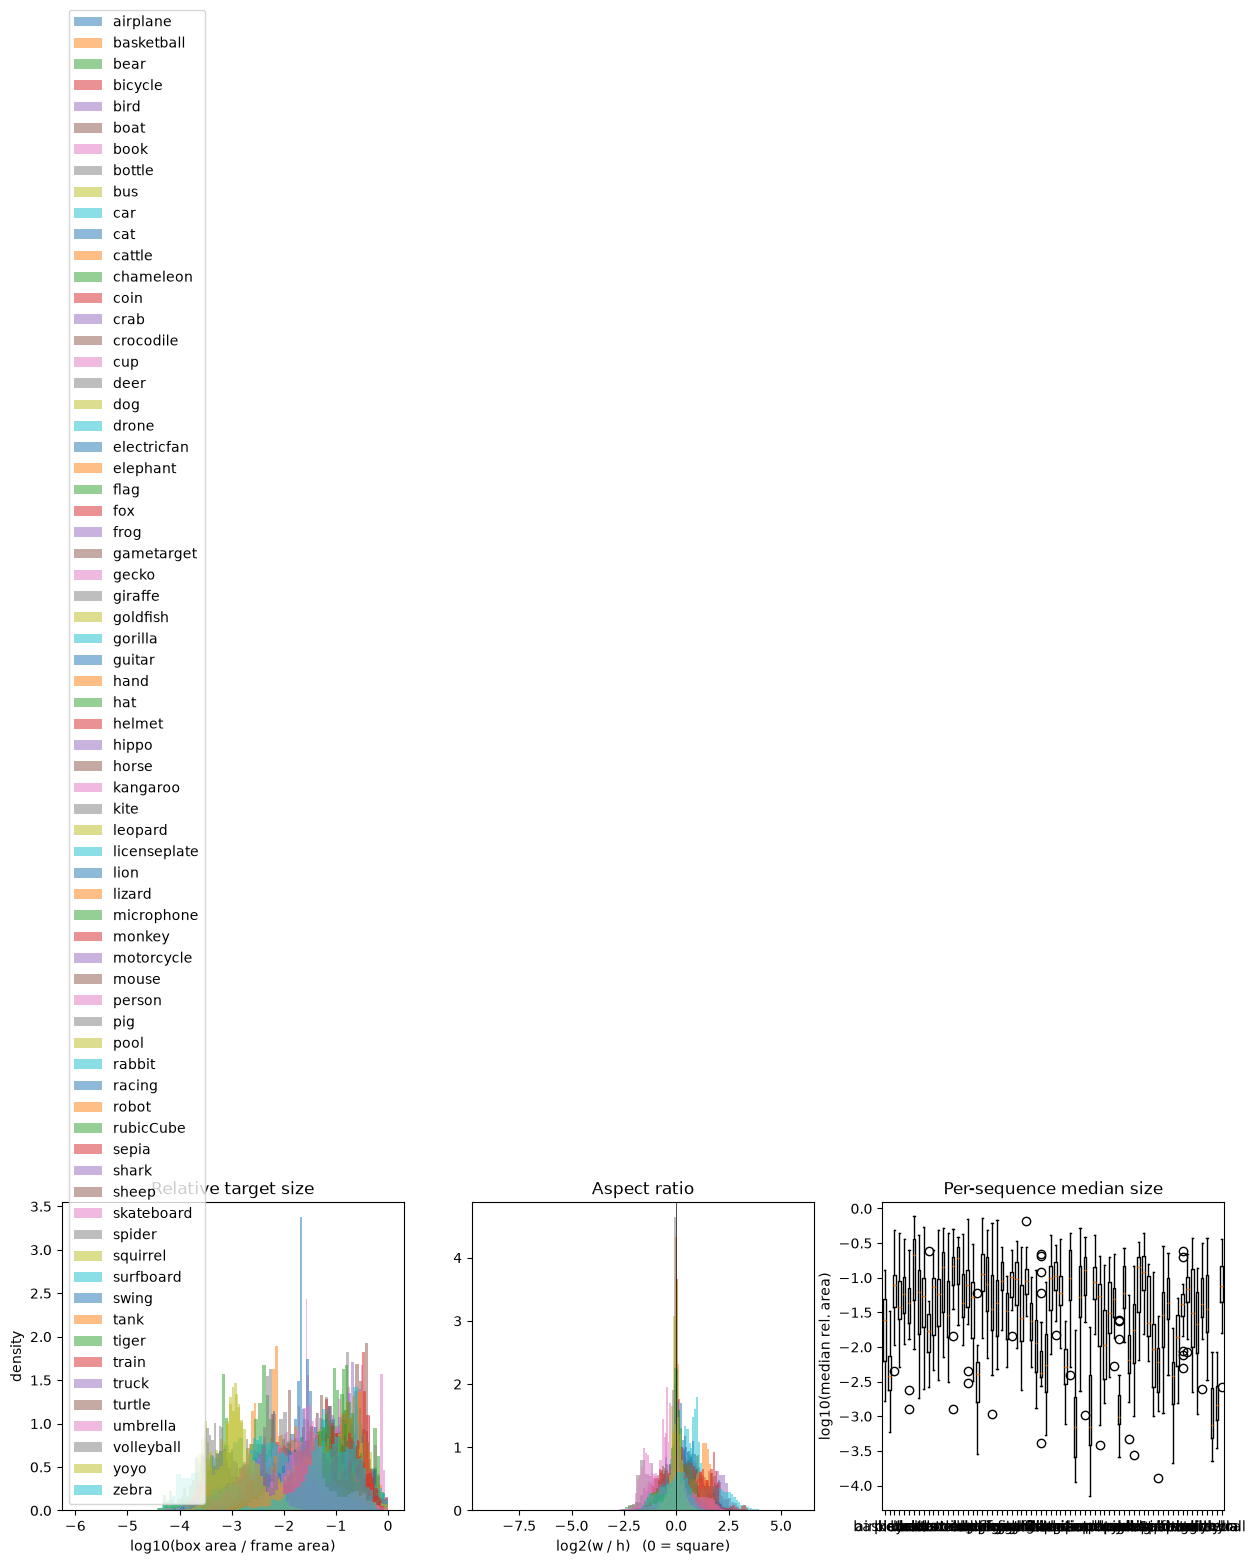

In [5]:
plots.plot_size_aspect(frames, save="size_aspect.png")
frames.groupby("cls")[["rel_area", "aspect"]].describe().T

## 3. Absent frames: full occlusion vs out-of-view

,frac_foc,frac_oov,frac_absent,n_foc_episodes,n_oov_episodes
cls,,,,,
airplane,0.001289,0.000611,0.001901,0.30,0.10
basketball,0.047447,0.019700,0.067121,14.75,3.80
bear,0.010408,0.006720,0.017113,0.60,0.65
bicycle,0.010917,0.007311,0.018227,1.00,0.60
bird,0.000998,0.002686,0.003684,0.40,0.55
...,...,...,...,...,...
turtle,0.007486,0.003864,0.011349,1.10,0.90
umbrella,0.002828,0.001795,0.004622,2.60,0.40
volleyball,0.014352,0.098304,0.112655,4.95,6.20


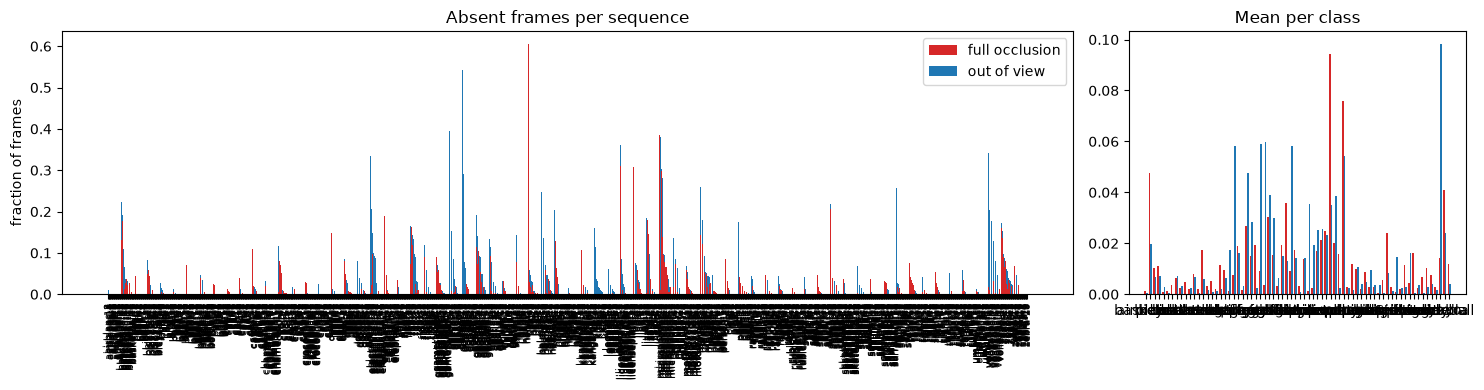

In [6]:
plots.plot_absence(seqs_df, save="absence.png")
seqs_df.groupby("cls")[["frac_foc", "frac_oov", "frac_absent", "n_foc_episodes", "n_oov_episodes"]].mean()

In [7]:
print("videos with FOC:", (seqs_df.n_foc > 0).sum(), "| with OOV:", (seqs_df.n_oov > 0).sum(), "| both flags on same frame:", (seqs_df.n_both > 0).sum())

videos with FOC: 522 | with OOV: 448 | both flags on same frame: 13


## 4. Video length and resolution

c:\Users\Mariia Hamaniuk\Desktop\jepa\Object-Tracking\src\eda\plots.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
airplane,20.0,4296.05,2776.756580,1101.0,2310.75,2929.5,5930.00,11397.0
basketball,20.0,2384.25,1334.670662,1010.0,1798.50,1920.0,2610.75,6841.0
bear,20.0,2700.90,1987.188596,1000.0,1321.50,1870.5,3116.25,7616.0
bicycle,20.0,2033.60,1085.580824,1000.0,1287.75,1632.5,2415.25,5200.0
bird,20.0,2431.65,1176.537662,1026.0,1531.50,2016.0,3083.25,5000.0
...,...,...,...,...,...,...,...,...
turtle,20.0,3249.20,2503.886760,1000.0,1438.50,2101.0,4546.75,9985.0
umbrella,20.0,3563.70,2402.059031,1001.0,1596.75,2570.0,5128.00,8444.0
volleyball,20.0,1557.70,415.078572,1057.0,1186.75,1533.5,1749.25,2606.0


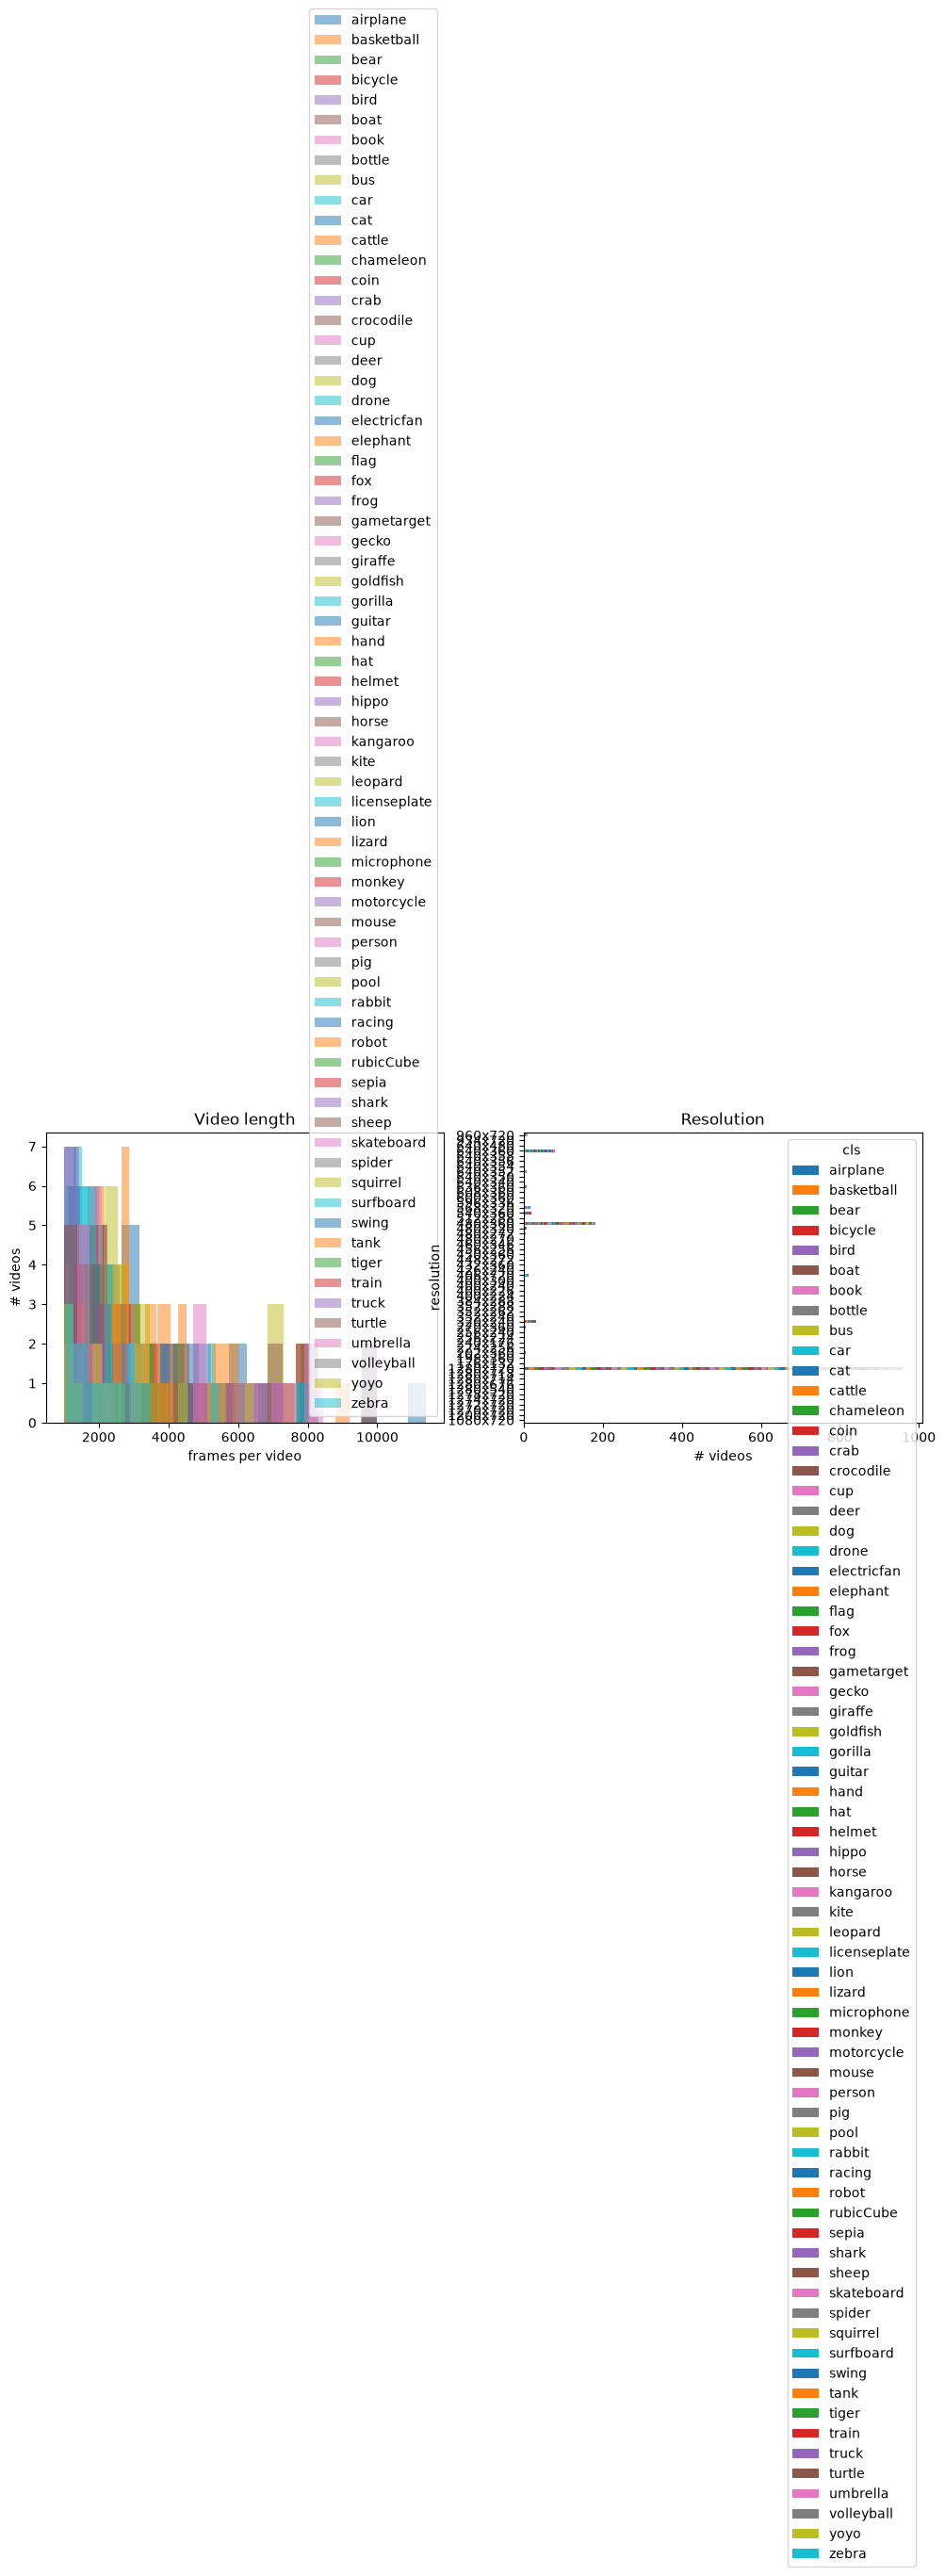

In [8]:
plots.plot_length_resolution(seqs_df, save="length_resolution.png")
seqs_df.groupby("cls").n_frames.describe()

## 5. Attributes
Official labels (`annos/*.txt`) are used once `C.ATTRIBUTE_ORDER` is set

,prevalence,SV,ARC,LR,FM,FOC,OV
0,0.160000,0.182143,0.231429,0.500714,0.589286,0.581429,0.620000
1,0.652143,0.650000,0.666429,0.525714,0.525714,0.629286,0.485000
2,0.517857,0.524286,0.592143,0.390000,0.435714,0.456429,0.493571
3,0.320714,0.340000,0.380714,0.541429,0.622857,0.575000,0.633571
4,0.309286,0.328571,0.362143,0.505714,0.557143,0.527857,0.592143
5,0.580000,0.587857,0.627143,0.503571,0.483571,0.495714,0.522857
6,0.310000,0.329286,0.362857,0.540714,0.567857,0.605714,0.580000
7,0.109286,0.141429,0.207857,0.534286,0.605714,0.580714,0.639286
8,0.943571,0.961429,0.890714,0.495714,0.375714,0.403571,0.363571
9,0.387143,0.413571,0.472857,0.705000,0.720714,0.975714,0.645714


c:\Users\Mariia Hamaniuk\Desktop\jepa\Object-Tracking\src\eda\plots.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


,SV,ARC,LR,FM,FOC,OV,IV,POC,DEF,MB,CM,ROT,BC,VC
cls,,,,,,,,,,,,,,
airplane,20,18,12,5,4,3,15,7,0,0,6,18,1,0
basketball,18,14,18,17,18,10,4,18,1,12,3,3,8,0
bear,20,19,2,3,3,4,5,17,20,4,11,5,5,0
bicycle,20,20,9,3,8,5,10,17,10,1,3,8,7,0
bird,20,19,6,3,5,5,4,14,15,3,10,2,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
turtle,19,17,8,2,8,3,2,4,20,4,8,10,4,5
umbrella,20,20,6,2,7,6,2,13,1,5,6,15,8,2
volleyball,15,16,20,16,14,18,0,16,0,20,0,0,2,0


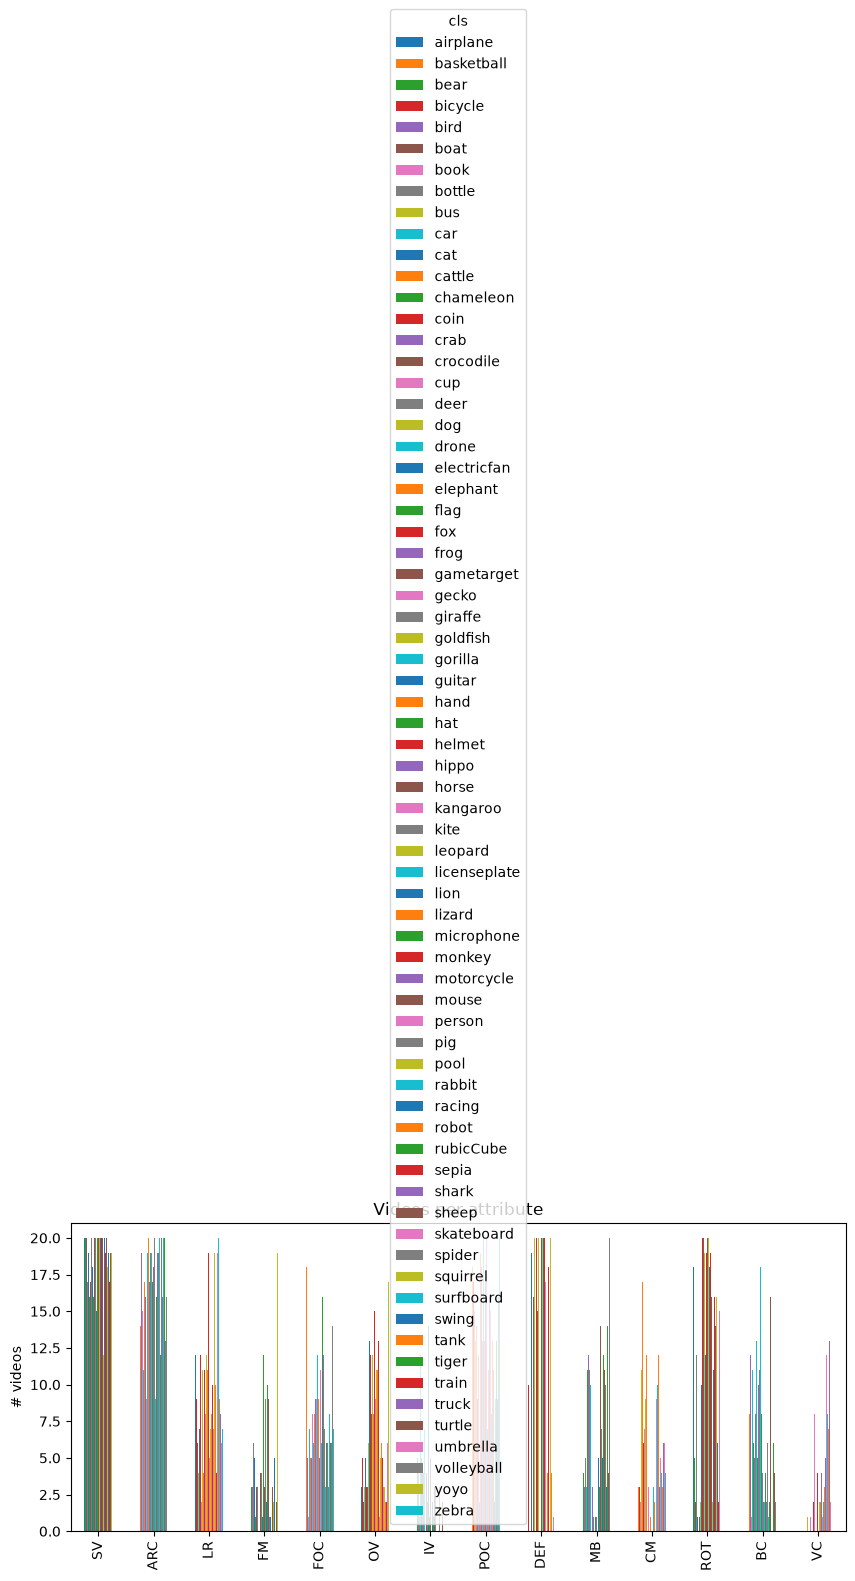

In [9]:
from src.data.lasot import load_attribute_matrix
derived = stats.derived_attributes(frames, seqs_df)
official = None
if C.ATTRIBUTE_DIR.exists():
    raw = load_attribute_matrix(C.ATTRIBUTE_DIR, seqs_df.seq)
    display(stats.check_attribute_columns(raw, derived))          # which file column is FOC / OV / ...?
    if C.ATTRIBUTE_ORDER:                                         # set in config.py after verifying
        official = stats.name_attribute_columns(raw, C.ATTRIBUTE_ORDER)
else:
    print("No official attributes at", C.ATTRIBUTE_DIR, "- using derived proxies only")
attr = stats.merge_official_attributes(derived, official)
counts = stats.attribute_counts(attr)
plots.plot_attribute_counts(counts, save="attribute_counts.png")
counts

## 6. Temporal density of occlusions / out-of-view

count       mean        std  min    25%   50%    75%    max
cls        kind                                                                 
airplane   full_occ    6.0  32.333333  46.966655  1.0   3.50  10.0  40.50  121.0
           out_view    2.0  23.000000  26.870058  4.0  13.50  23.0  32.50   42.0
basketball full_occ  295.0   6.589831  13.171988  1.0   1.00   2.0   6.00  144.0
           out_view   76.0   8.736842  11.133575  1.0   2.00   6.0  11.25   68.0
bear       full_occ   12.0  19.666667  22.083862  1.0   9.25  11.5  19.00   73.0
...                    ...        ...        ...  ...    ...   ...    ...    ...
volleyball out_view  124.0  24.016129  13.763380  1.0  14.75  21.5  32.00   62.0
yoyo       full_occ  689.0   3.867925   5.837053  1.0   1.00   2.0   4.00   68.0
           out_view  216.0   6.712963   7.085591  1.0   2.00   4.0   9.00   43.0
zebra      full_occ   29.0  14.000000  15.219818  1.0   3.00  10.0  20.00   72.0
           out_view   14.0  24.857143  24.679039  1.0   2.75  17.0  39.00   72.0

[138 rows x 8 columns]

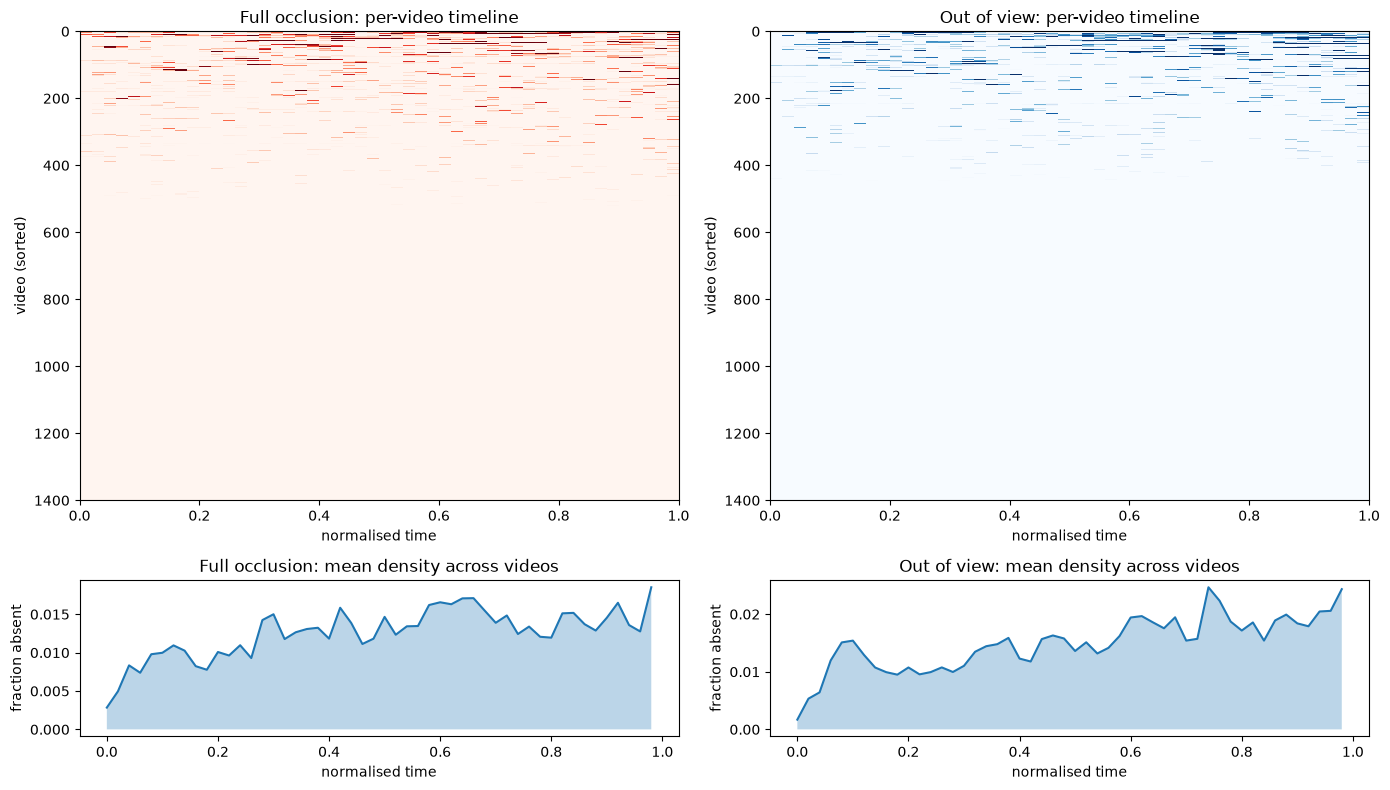

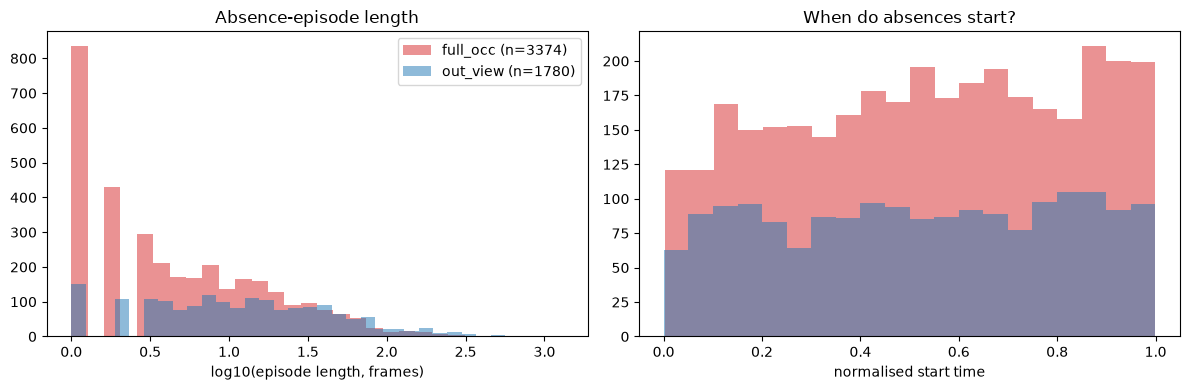

In [10]:
dens_foc = stats.temporal_density(seqs, "full_occ")
dens_oov = stats.temporal_density(seqs, "out_view")
episodes = stats.episodes_table(seqs)
plots.plot_temporal_density(dens_foc, dens_oov, save="temporal_density.png")
plots.plot_episodes(episodes, save="episodes.png")
episodes.groupby(["cls", "kind"]).length.describe()

## 7. Do the test videos cover a spread of attributes?

blind spots (class, attribute): [('airplane', 'FOC'), ('airplane', 'DEF'), ('airplane', 'MB'), ('airplane', 'BC'), ('airplane', 'VC'), ('basketball', 'DEF'), ('basketball', 'CM'), ('basketball', 'ROT'), ('basketball', 'VC'), ('bear', 'LR'), ('bear', 'FM'), ('bear', 'FOC'), ('bear', 'IV'), ('bear', 'BC'), ('bear', 'VC'), ('bicycle', 'MB'), ('bicycle', 'CM'), ('bicycle', 'VC'), ('bird', 'FM'), ('bird', 'ROT'), ('bird', 'VC'), ('boat', 'FM'), ('boat', 'FOC'), ('boat', 'OV'), ('boat', 'IV'), ('boat', 'DEF'), ('boat', 'MB'), ('boat', 'ROT'), ('boat', 'BC'), ('book', 'LR'), ('book', 'FM'), ('book', 'FOC'), ('book', 'OV'), ('book', 'IV'), ('book', 'CM'), ('book', 'BC'), ('book', 'VC'), ('bottle', 'IV'), ('bottle', 'DEF'), ('bottle', 'VC'), ('bus', 'OV'), ('bus', 'DEF'), ('bus', 'ROT'), ('bus', 'VC'), ('car', 'OV'), ('car', 'DEF'), ('car', 'ROT'), ('car', 'VC'), ('cat', 'FM'), ('cat', 'OV'), ('cat', 'IV'), ('cat', 'ROT'), ('cat', 'VC'), ('cattle', 'FOC'), ('cattle', 'IV'), ('cattle', 'ROT'), (

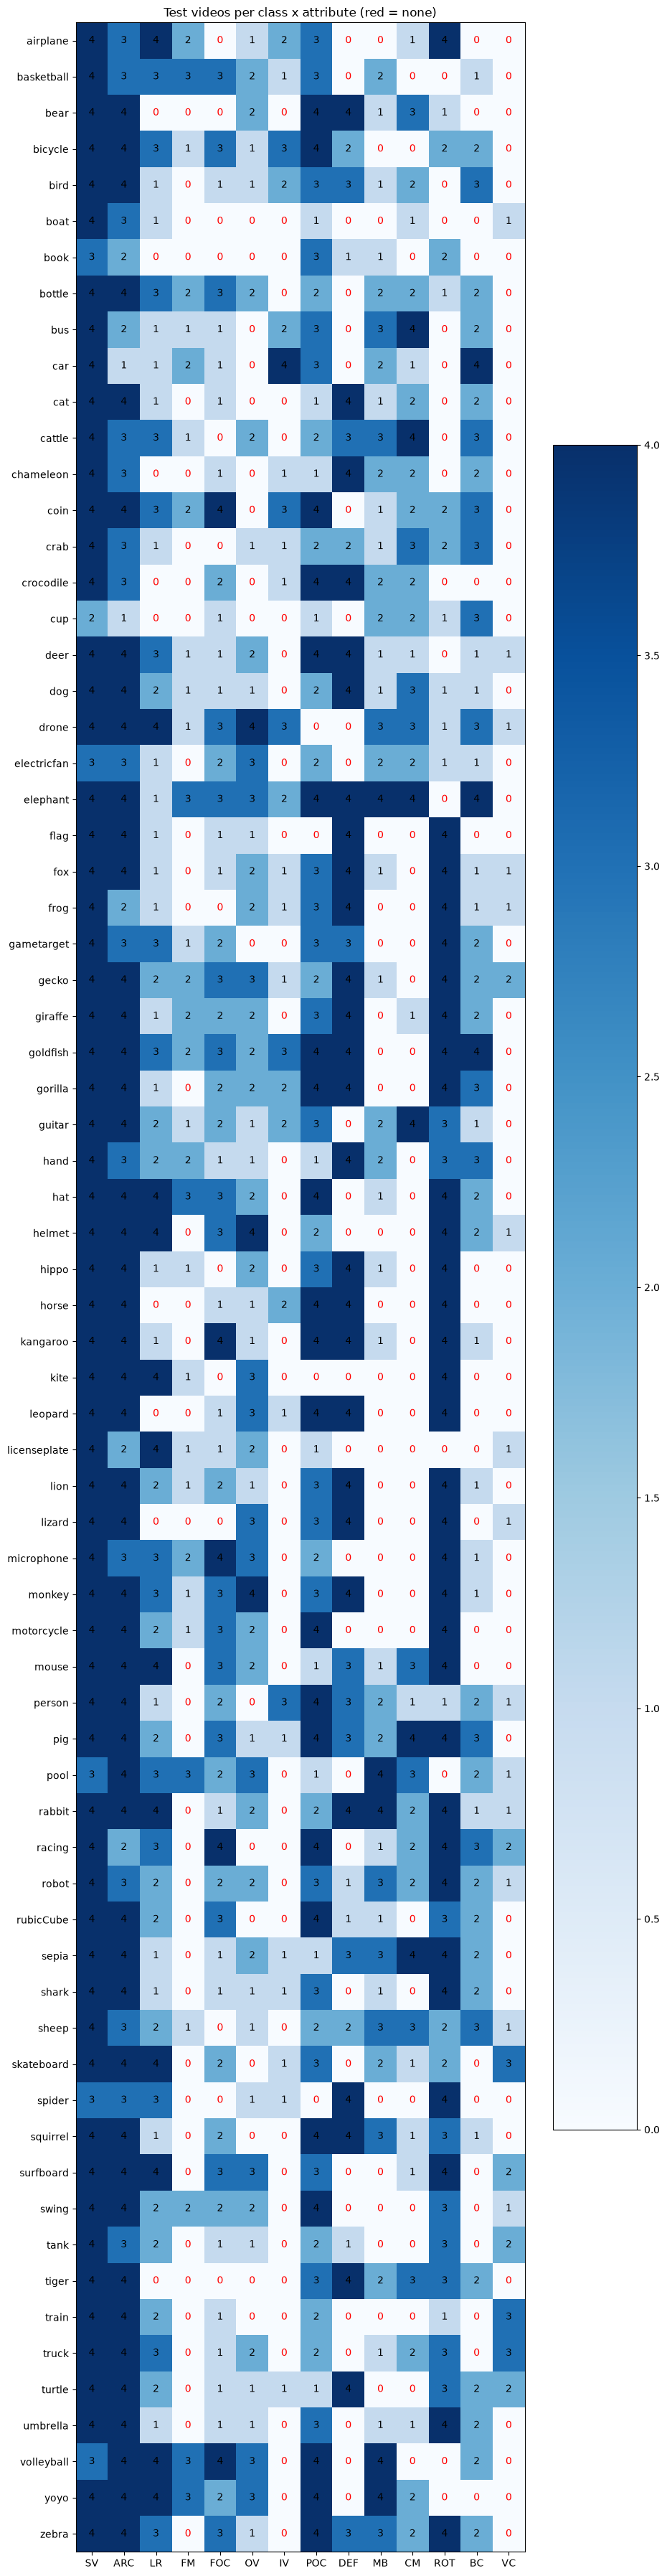

In [11]:
test = read_split(C.SPLIT_FILE)
if test is None:
    print("No split file at", C.SPLIT_FILE, "- download the official test list first.")
else:
    cov = stats.coverage_table(attr, test)
    plots.plot_coverage(cov, save="test_coverage.png")
    print("blind spots (class, attribute):", [(c, a) for c in cov.index for a in cov.columns if cov.loc[c, a] == 0])
    cov

## 8. Visual sanity check of annotations

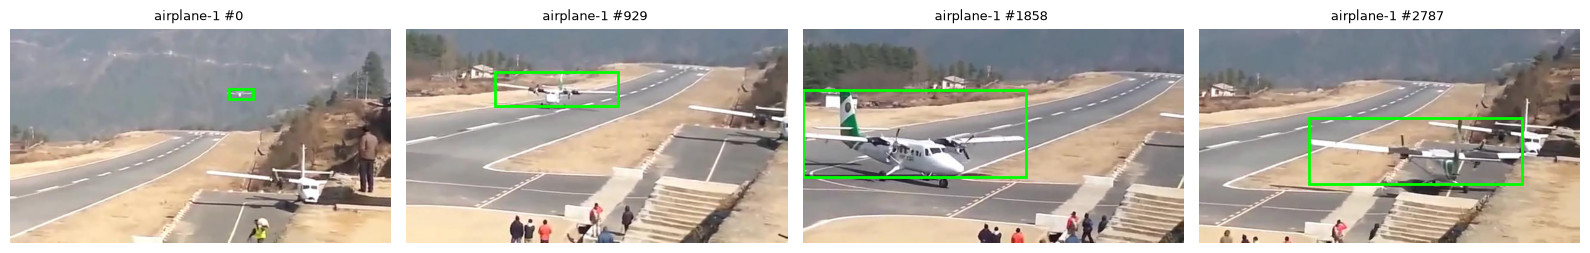

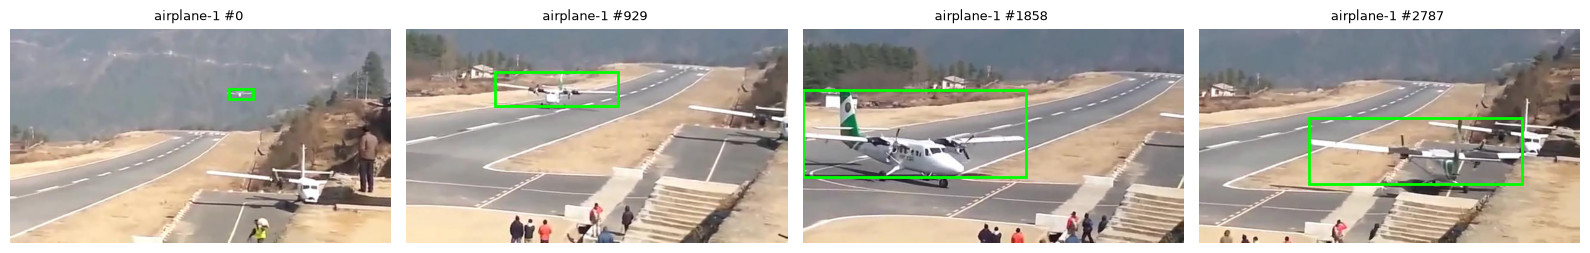

In [12]:
plots.show_samples(seqs[0], n=4)

## 9. Save tables (small CSVs can be committed)

In [13]:
seqs_df.to_csv(C.RESULTS_DIR / "sequences.csv", index=False)
counts.to_csv(C.RESULTS_DIR / "attribute_counts.csv")
episodes.to_csv(C.RESULTS_DIR / "episodes.csv", index=False)
attr.to_csv(C.RESULTS_DIR / "attributes_per_sequence.csv")